# 02 — Limpeza dos dados e análise exploratória

**TCC UNIP 2026** · Etapa 2 de 9 do pipeline · Seção 4.5.2 do trabalho escrito.

**Objetivo:** consolidar os metadados das sete classes, verificar a integridade das imagens, remover duplicatas e descrever a base (classes, idade, sexo, localização anatômica e confirmação diagnóstica).

**Entradas:**
- `/content/data/isic/<classe>/` (notebook 01)

**Saídas:**
- `/content/data/processed/dataset_limpo.csv`
- `/content/data/processed/composicao_base.csv`
- `/content/data/processed/eda_*.png`

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


In [ ]:
# [Célula reutilizada de 01_coleta_ingestao.ipynb]
CLASSES_ISIC = {
    "melanoma": 'diagnosis_2:"Malignant melanocytic proliferations (Melanoma)"',
    "nevo_melanocitico": 'diagnosis_3:"Nevus"',
    "carcinoma_basocelular": 'diagnosis_3:"Basal cell carcinoma"',
    "ceratose_actinica": 'diagnosis_3:"Solar or actinic keratosis"',
    "ceratose_seborreica": 'diagnosis_3:"Seborrheic keratosis"',
    "dermatofibroma": 'diagnosis_3:"Dermatofibroma"',
    "lesao_vascular": 'diagnosis_2:"Benign soft tissue proliferations - Vascular"',
}

In [ ]:
import os
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

In [ ]:
sns.set_theme(style="whitegrid")

In [ ]:
DESTINO_BASE = "/content/data/isic"
SAIDA_BASE = "/content/data/processed"
os.makedirs(SAIDA_BASE, exist_ok=True)

In [ ]:
# ============================================================
# 1. CONSOLIDAÇÃO — juntar os 7 metadata.csv num único DataFrame
# ============================================================
def consolidar_metadados():
    dfs = []
    for pasta in sorted(os.listdir(DESTINO_BASE)):
        caminho_csv = os.path.join(DESTINO_BASE, pasta, "metadata.csv")
        if not os.path.exists(caminho_csv):
            print(f"[AVISO] Sem metadata.csv em {pasta}, pulando.")
            continue

        df = pd.read_csv(caminho_csv)
        df["classe"] = pasta  # rótulo derivado do nome da pasta (a nossa "ground truth" de trabalho)
        df["caminho_pasta"] = os.path.join(DESTINO_BASE, pasta)
        dfs.append(df)
        print(f"{pasta}: {len(df)} registros carregados")

    df_completo = pd.concat(dfs, ignore_index=True)
    print(f"\nTotal consolidado: {len(df_completo)} registros")
    return df_completo

In [ ]:
# ============================================================
# 2. LIMPEZA
# ============================================================

def identificar_coluna_id(df):
    """Detecta automaticamente qual coluna tem o identificador da imagem."""
    candidatos = ["isic_id", "image_id", "id", "name"]
    for c in candidatos:
        if c in df.columns:
            return c
    raise ValueError(f"Não achei coluna de ID. Colunas disponíveis: {list(df.columns)}")

In [ ]:
def encontrar_caminho_imagem(row, col_id):
    """Monta o caminho físico do arquivo de imagem para uma linha do DataFrame."""
    for ext in [".jpg", ".jpeg", ".png", ".JPG", ".PNG"]:
        caminho = os.path.join(row["caminho_pasta"], f"{row[col_id]}{ext}")
        if os.path.exists(caminho):
            return caminho
    return None

In [ ]:

def validar_imagens(df, col_id):
    """Verifica arquivos corrompidos ou ausentes."""
    caminhos = []
    corrompidas = []
    ausentes = []

    for _, row in df.iterrows():
        caminho = encontrar_caminho_imagem(row, col_id)
        if caminho is None:
            ausentes.append(row[col_id])
            caminhos.append(None)
            continue
        try:
            with Image.open(caminho) as img:
                img.verify()
            caminhos.append(caminho)
        except Exception:
            corrompidas.append(caminho)
            caminhos.append(None)

    df["caminho_imagem"] = caminhos
    print(f"Imagens ausentes (sem arquivo): {len(ausentes)}")
    print(f"Imagens corrompidas: {len(corrompidas)}")
    return df, ausentes, corrompidas

In [ ]:
def calcular_hash_imagem(caminho):
    """Hash MD5 do conteúdo do arquivo, para detectar duplicatas exatas."""
    try:
        with open(caminho, "rb") as f:
            return hashlib.md5(f.read()).hexdigest()
    except Exception:
        return None

In [ ]:
def remover_duplicatas(df):
    """Remove duplicatas exatas (mesmo conteúdo de arquivo) e por isic_id repetido."""
    antes = len(df)

    # Duplicata por ID (mesma imagem baixada em mais de uma classe, por exemplo)
    col_id = identificar_coluna_id(df)
    df = df.drop_duplicates(subset=col_id, keep="first")

    # Duplicata por conteúdo de arquivo (hash) — mais caro, mas pega imagens
    # idênticas com nomes diferentes
    print("Calculando hashes das imagens (pode levar alguns minutos)...")
    df["hash_arquivo"] = df["caminho_imagem"].apply(
        lambda c: calcular_hash_imagem(c) if c else None
    )
    df = df.drop_duplicates(subset="hash_arquivo", keep="first")

    depois = len(df)
    print(f"Registros antes: {antes} | depois de remover duplicatas: {depois} "
          f"({antes - depois} removidos)")
    return df

In [ ]:
def limpar_dataset(df):
    col_id = identificar_coluna_id(df)

    print("\n--- Validando integridade das imagens ---")
    df, ausentes, corrompidas = validar_imagens(df, col_id)

    # Remove linhas sem imagem válida
    df_valido = df[df["caminho_imagem"].notna()].copy()
    print(f"Registros com imagem válida: {len(df_valido)} de {len(df)}")

    print("\n--- Removendo duplicatas ---")
    df_valido = remover_duplicatas(df_valido)

    # Marca separadamente os casos confirmados só clinicamente (não descarta,
    # como orienta o item 3.5 do TCC — só etiqueta para poder isolar depois)
    if "confirmacao_tipo" in df_valido.columns:
        df_valido["confirmado_histopatologia"] = (
            df_valido["confirmacao_tipo"] == "histopathology"
        )
    elif "diagnosis_confirm_type" in df_valido.columns:
        df_valido["confirmado_histopatologia"] = (
            df_valido["diagnosis_confirm_type"] == "histopathology"
        )

    return df_valido

In [ ]:
# ============================================================
# 3. EDA — distribuição de classes, idade, sexo
# ============================================================

def eda_distribuicao_classes(df):
    plt.figure(figsize=(10, 5))
    ordem = df["classe"].value_counts().index
    sns.countplot(data=df, y="classe", order=ordem, palette="viridis")
    plt.title("Distribuição de imagens por classe diagnóstica")
    plt.xlabel("Quantidade de imagens")
    plt.ylabel("Classe")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_classes.png"), dpi=150)
    plt.show()

    print("\nContagem exata por classe:")
    print(df["classe"].value_counts())
    print("\nProporção (%) por classe:")
    print((df["classe"].value_counts(normalize=True) * 100).round(2))

In [ ]:
def eda_idade(df, col_idade="idade"):
    if col_idade not in df.columns:
        col_idade = "age_approx" if "age_approx" in df.columns else None
    if col_idade is None:
        print("[AVISO] Nenhuma coluna de idade encontrada, pulando essa análise.")
        return

    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=col_idade, hue="classe", multiple="stack", bins=20)
    plt.title("Distribuição de idade dos pacientes por classe")
    plt.xlabel("Idade aproximada")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_idade.png"), dpi=150)
    plt.show()

    print(f"\nEstatísticas de idade (coluna '{col_idade}'):")
    print(df[col_idade].describe())
    print(f"\nRegistros sem idade informada: {df[col_idade].isna().sum()} "
          f"({df[col_idade].isna().mean()*100:.1f}%)")

In [ ]:
def eda_sexo(df, col_sexo="sexo"):
    if col_sexo not in df.columns:
        col_sexo = "sex" if "sex" in df.columns else None
    if col_sexo is None:
        print("[AVISO] Nenhuma coluna de sexo encontrada, pulando essa análise.")
        return

    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x="classe", hue=col_sexo)
    plt.title("Distribuição de sexo por classe")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_distribuicao_sexo.png"), dpi=150)
    plt.show()

    print(f"\nDistribuição geral de sexo (coluna '{col_sexo}'):")
    print(df[col_sexo].value_counts(dropna=False))
    print(f"\nRegistros sem sexo informado: {df[col_sexo].isna().sum()} "
          f"({df[col_sexo].isna().mean()*100:.1f}%)")

In [ ]:
def eda_localizacao_anatomica(df):
    col = None
    for candidato in ["localizacao_anatomica", "anatom_site_general", "anatom_site_1"]:
        if candidato in df.columns:
            col = candidato
            break
    if col is None:
        print("[AVISO] Nenhuma coluna de localização anatômica encontrada.")
        return

    plt.figure(figsize=(10, 6))
    ordem = df[col].value_counts().index
    sns.countplot(data=df, y=col, order=ordem, palette="mako")
    plt.title("Distribuição por localização anatômica da lesão")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_localizacao_anatomica.png"), dpi=150)
    plt.show()

In [ ]:
def eda_confirmacao_diagnostica(df):
    if "confirmado_histopatologia" not in df.columns:
        print("[AVISO] Coluna de confirmação diagnóstica não disponível.")
        return

    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x="classe", hue="confirmado_histopatologia")
    plt.title("Proporção de confirmação por histopatologia vs. clínica, por classe")
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Confirmado por histopatologia")
    plt.tight_layout()
    plt.savefig(os.path.join(SAIDA_BASE, "eda_confirmacao_diagnostica.png"), dpi=150)
    plt.show()

    print("\nProporção de confirmação histopatológica por classe (%):")
    print((df.groupby("classe")["confirmado_histopatologia"].mean() * 100).round(1))

In [ ]:
def relatorio_valores_ausentes(df):
    print("\n--- Percentual de valores ausentes por coluna ---")
    ausentes = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
    print(ausentes[ausentes > 0])

ETAPA 1: Consolidação dos metadados
carcinoma_basocelular: 3323 registros carregados
ceratose_actinica: 867 registros carregados
ceratose_seborreica: 1316 registros carregados
dermatofibroma: 239 registros carregados
lesao_vascular: 253 registros carregados
melanoma: 4522 registros carregados
nevo_melanocitico: 12871 registros carregados

Total consolidado: 23391 registros

ETAPA 2: Limpeza

--- Validando integridade das imagens ---
Imagens ausentes (sem arquivo): 0
Imagens corrompidas: 0
Registros com imagem válida: 23391 de 23391

--- Removendo duplicatas ---
Calculando hashes das imagens (pode levar alguns minutos)...
Registros antes: 23391 | depois de remover duplicatas: 23391 (0 removidos)

ETAPA 3: Análise Exploratória de Dados (EDA)


/tmp/ipykernel_960/2845209299.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="classe", order=ordem, palette="viridis")


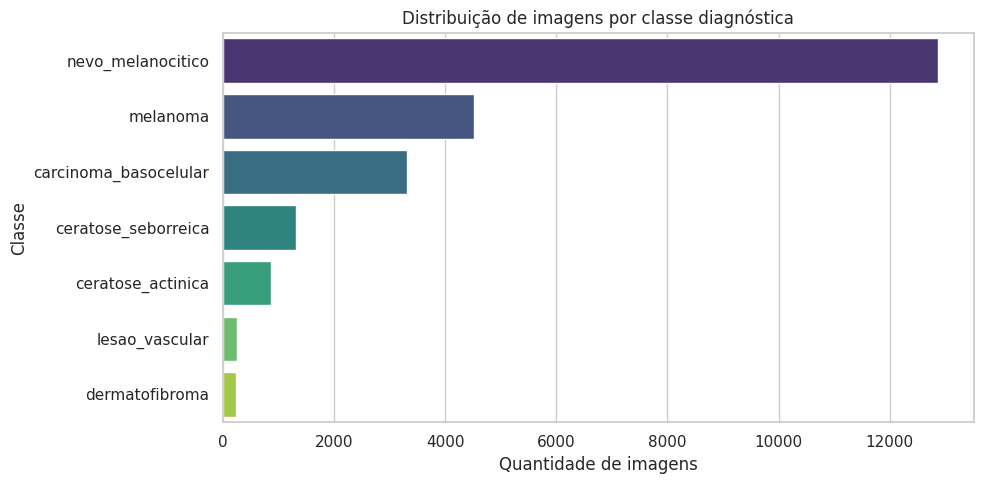


Contagem exata por classe:
classe
nevo_melanocitico        12871
melanoma                  4522
carcinoma_basocelular     3323
ceratose_seborreica       1316
ceratose_actinica          867
lesao_vascular             253
dermatofibroma             239
Name: count, dtype: int64

Proporção (%) por classe:
classe
nevo_melanocitico        55.03
melanoma                 19.33
carcinoma_basocelular    14.21
ceratose_seborreica       5.63
ceratose_actinica         3.71
lesao_vascular            1.08
dermatofibroma            1.02
Name: proportion, dtype: float64


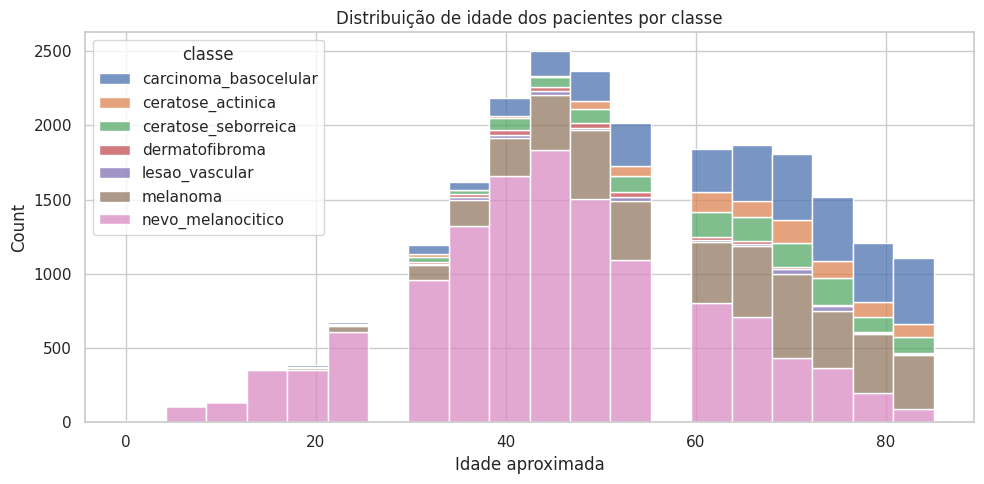


Estatísticas de idade (coluna 'age_approx'):
count    22925.000000
mean        53.069357
std         17.939948
min          0.000000
25%         40.000000
50%         50.000000
75%         65.000000
max         85.000000
Name: age_approx, dtype: float64

Registros sem idade informada: 466 (2.0%)


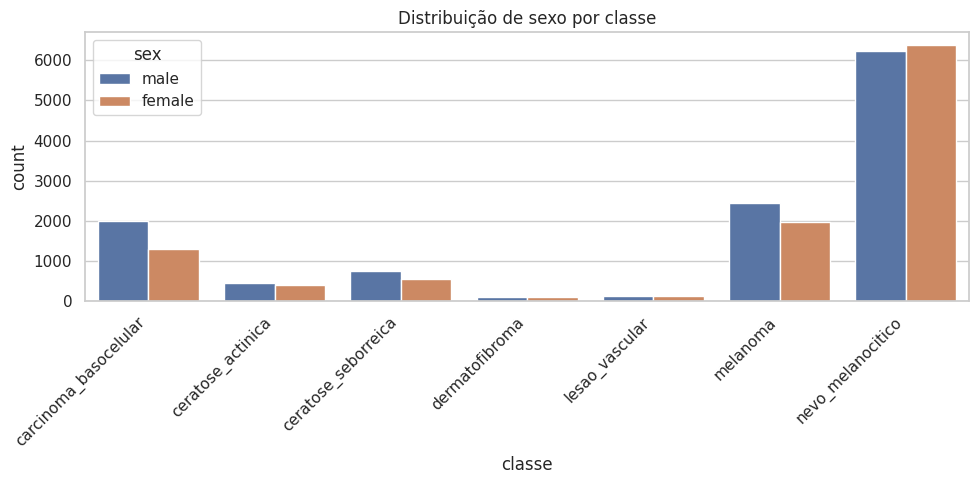


Distribuição geral de sexo (coluna 'sex'):
sex
male      12144
female    10874
NaN         373
Name: count, dtype: int64

Registros sem sexo informado: 373 (1.6%)


/tmp/ipykernel_960/2899018900.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y=col, order=ordem, palette="mako")


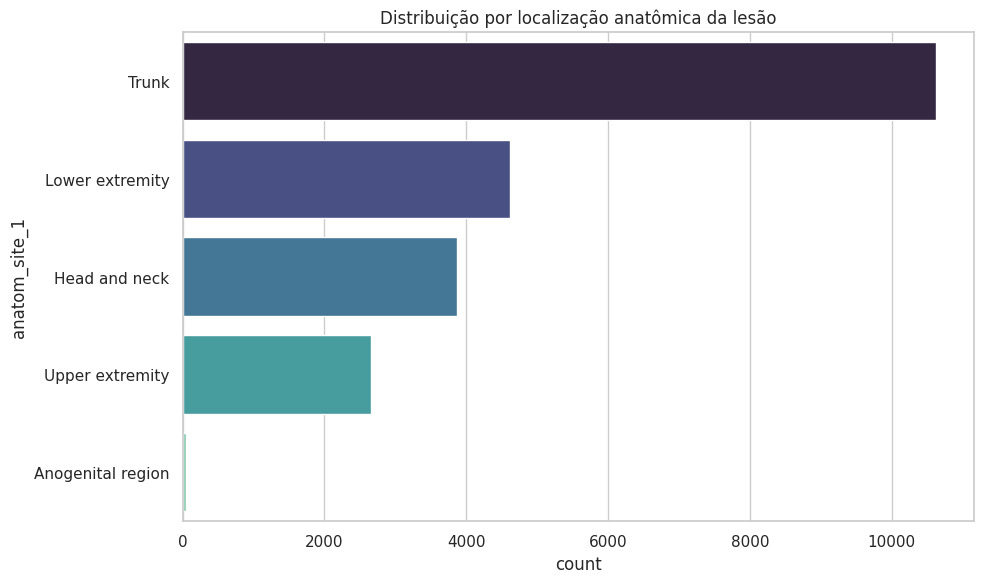

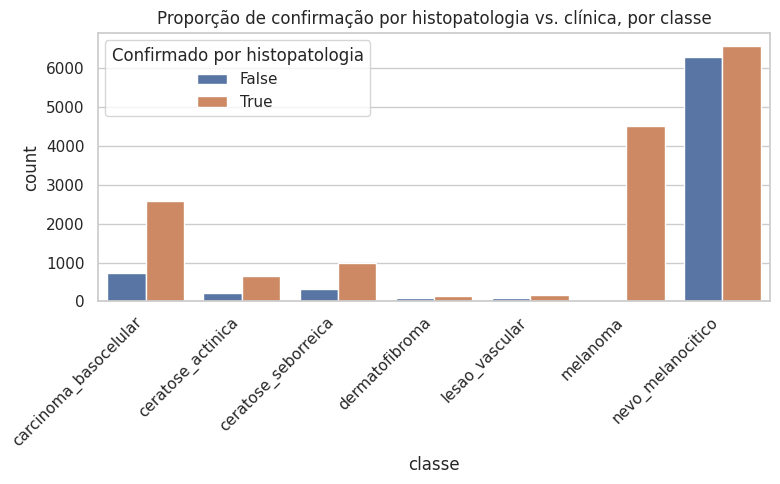


Proporção de confirmação histopatológica por classe (%):
classe
carcinoma_basocelular     78.1
ceratose_actinica         75.7
ceratose_seborreica       74.8
dermatofibroma            61.9
lesao_vascular            62.5
melanoma                 100.0
nevo_melanocitico         51.1
Name: confirmado_histopatologia, dtype: float64

--- Percentual de valores ausentes por coluna ---
anatom_site_5             99.83
anatom_site_4             98.98
diagnosis_5               98.23
patient_id                98.22
family_hx_mm              97.68
clin_size_long_diam_mm    97.64
personal_hx_mm            97.64
anatom_site_special       96.09
diagnosis_4               95.83
dermoscopic_type          93.89
anatom_site_3             88.73
anatom_site_2             52.99
diagnosis_confirm_type     9.92
lesion_id                  7.11
anatom_site_1              6.70
age_approx                 1.99
sex                        1.59
diagnosis_3                1.08
dtype: float64

Dataset limpo salvo em: /co

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("=" * 60)
    print("ETAPA 1: Consolidação dos metadados")
    print("=" * 60)
    df_bruto = consolidar_metadados()

    print("\n" + "=" * 60)
    print("ETAPA 2: Limpeza")
    print("=" * 60)
    df_limpo = limpar_dataset(df_bruto)

    print("\n" + "=" * 60)
    print("ETAPA 3: Análise Exploratória de Dados (EDA)")
    print("=" * 60)
    eda_distribuicao_classes(df_limpo)
    eda_idade(df_limpo)
    eda_sexo(df_limpo)
    eda_localizacao_anatomica(df_limpo)
    eda_confirmacao_diagnostica(df_limpo)
    relatorio_valores_ausentes(df_limpo)

    # Salva o dataset limpo para as próximas etapas (pré-processamento)
    caminho_saida = os.path.join(SAIDA_BASE, "dataset_limpo.csv")
    df_limpo.to_csv(caminho_saida, index=False)
    print(f"\nDataset limpo salvo em: {caminho_saida}")
    print(f"Total final de registros: {len(df_limpo)}")


In [ ]:
# ============================================================
# DOCUMENTAÇÃO DA COMPOSIÇÃO DA BASE EFETIVAMENTE UTILIZADA
# ============================================================
# Esta célula registra quantitativos reais após coleta e limpeza; não presume que a amostra
# obtida pela API equivale à coleção completa ISIC 2019.

def salvar_composicao_base(df, nome_arquivo="composicao_base.csv"):
    colunas = [c for c in ["classe", "diagnosis", "diagnosis_2", "diagnosis_3", "isic_id", "lesion_id", "patient_id"] if c in df.columns]
    resumo = df.groupby("classe", dropna=False).size().rename("n_registros_limpos").reset_index()
    resumo["percentual_base_limpa"] = (100 * resumo["n_registros_limpos"] / max(1, len(df))).round(3)
    resumo.to_csv(os.path.join(SAIDA_BASE, nome_arquivo), index=False)
    print("Total após limpeza:", len(df))
    print(resumo.to_string(index=False))
    print("Classes consultadas pela API (dicionário CLASSES_ISIC):")
    for classe, consulta in CLASSES_ISIC.items():
        print(f"- {classe}: {consulta}")
    print("Observação: para declarar cobertura total/parcial da coleção, compare estes totais com a documentação oficial ISIC 2019 e registre os filtros de consulta.")
    return resumo

if __name__ == "__main__":
    if os.path.exists(os.path.join(SAIDA_BASE, "dataset_limpo.csv")):
        _df_comp = pd.read_csv(os.path.join(SAIDA_BASE, "dataset_limpo.csv"), low_memory=False)
        salvar_composicao_base(_df_comp)
    else:
        print("Execute primeiro a limpeza para gerar dataset_limpo.csv.")


Total após limpeza: 23391
               classe  n_registros_limpos  percentual_base_limpa
carcinoma_basocelular                3323                 14.206
    ceratose_actinica                 867                  3.707
  ceratose_seborreica                1316                  5.626
       dermatofibroma                 239                  1.022
       lesao_vascular                 253                  1.082
             melanoma                4522                 19.332
    nevo_melanocitico               12871                 55.025
Classes consultadas pela API (dicionário CLASSES_ISIC):
- melanoma: diagnosis_2:"Malignant melanocytic proliferations (Melanoma)"
- nevo_melanocitico: diagnosis_3:"Nevus"
- carcinoma_basocelular: diagnosis_3:"Basal cell carcinoma"
- ceratose_actinica: diagnosis_3:"Solar or actinic keratosis"
- ceratose_seborreica: diagnosis_3:"Seborrheic keratosis"
- dermatofibroma: diagnosis_3:"Dermatofibroma"
- lesao_vascular: diagnosis_2:"Benign soft tissue prolif